# GPU Infrastructure and LLM Serving on Kubernetes

> **Who is this for:** people who know basic Kubernetes (Pods, Deployments, Services, scheduling) and want to run GPU training and LLM inference on it: platform engineers, MLOps engineers, and ML engineers who have to talk to them.
>
> **What you will learn:**
> - the **GPU software stack** for operators: drivers, CUDA, the NVIDIA Container Toolkit, the **GPU Operator**, the device plugin, and **DCGM** metrics
> - **sharing a GPU**: MIG, time-slicing and MPS (with a runnable bin-packing toy that compares utilisation)
> - **Dynamic Resource Allocation (DRA)** and ResourceClaims, the new way to request devices
> - **batch and gang scheduling** with Kueue, Volcano and the KAI Scheduler (with a runnable deadlock demo)
> - **AMD GPUs** and ROCm
> - the **LLM serving stacks**: Triton, KServe, vLLM production stack, llm-d, NVIDIA Dynamo, NVIDIA NIM, Ray Serve / KubeRay, SGLang
> - the **Gateway API Inference Extension** and KV-cache-aware routing (with a runnable router comparison)
> - **autoscaling LLM servers** on queue depth and KV-cache use, including cold starts (runnable)
> - **model loading and caching**, **multi-node training** (Kubeflow Trainer, JobSet) vs **Slurm**, and **GPU networking** (NVLink, InfiniBand, RDMA, EFA)
> - **GPU clouds and neoclouds**, on-prem / air-gapped and hybrid setups, the **CNCF Kubernetes AI Conformance** program
> - **container runtimes and build tools**: containerd, CRI-O, runc, Podman/Buildah, BuildKit/buildx multi-arch, dev containers
> - a **cost per million tokens** model (illustrative numbers)
>
> **Prerequisites:** [Kubernetes deep dive for AI workloads](02_kubernetes_deep_dive_for_ai_workloads.ipynb), [LLM inference optimization](../../08_LLM/13_inference_optimization.ipynb) (KV cache, batching), [LLM caching and KV-aware routing](../../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb). Helpful: [distributed training](../../05_Deep_Learning/11_distributed_training.ipynb), [Docker for ML](../02_docker_for_ml.ipynb).
>
> **Time needed:** about 3 hours to read; the code runs in a few seconds.
>
> **Runs on:** CPU, no GPU, no cluster, no API key, no internet. All GPU behaviour is **simulated** in small pure-Python toys so you can see the logic. Manifests and commands are shown as YAML/bash in markdown. All throughput, timing and price numbers are **illustrative**, chosen to show trade-offs, not measured benchmarks.

**Version note.** This field moves fast. Product names, versions and statuses below are as of **late 2026** (Kubernetes 1.37 is the newest release) and were checked against official pages and release notes; treat them as a snapshot and check the linked docs before you build on them.

## 0. Setup

In [1]:
import math, random, heapq, shutil, itertools, json, re
from collections import defaultdict, Counter, OrderedDict, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 7
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 140)

HAS_NVIDIA_SMI = shutil.which("nvidia-smi") is not None
print("nvidia-smi found:", HAS_NVIDIA_SMI, "(not needed: everything here is simulated)")

nvidia-smi found: False (not needed: everything here is simulated)


## 1. GPU basics for operators

### 1.1 The software stack, bottom to top

**What it is.** For a container to use an NVIDIA GPU, several layers must line up:

| Layer | What it is | Where it lives |
|---|---|---|
| **GPU hardware** | for example L4, L40S, A100, H100/H200, B200, GB200/GB300 | the node |
| **Kernel driver** | the NVIDIA driver; it decides which CUDA versions can run | the node (host), never inside your image |
| **CUDA toolkit / runtime, cuDNN, NCCL** | libraries your framework calls (matrix maths, convolutions, multi-GPU communication) | **inside your container image** (for example a `pytorch/pytorch` or `nvcr.io/nvidia/pytorch` image) |
| **NVIDIA Container Toolkit** | hooks the container runtime so a container can see the GPU device files and the host driver libraries; uses **CDI** (Container Device Interface), a vendor-neutral spec that describes devices to runtimes | the node |
| **Device plugin** or **DRA driver** | tells Kubernetes "this node has 8 GPUs" and hands specific GPUs to Pods | a DaemonSet |
| **Your Pod** | asks for `nvidia.com/gpu: 1` (device plugin) or a ResourceClaim (DRA) | the cluster |

**Simple analogy.** The GPU is a car engine. The driver is the gearbox that only accepts certain engine versions. CUDA is the set of tools your mechanic (PyTorch) brought in their own toolbox (the image). The container toolkit is the garage door that lets the mechanic reach the engine. The device plugin is the receptionist who tells the booking system how many engines are free.

**The rule that bites everyone:** the host **driver** must be new enough for the **CUDA version in your image**. A new image on an old driver fails with errors like "CUDA driver version is insufficient". Pin both, and upgrade drivers before images.

### 1.2 The NVIDIA GPU Operator

**What it is.** An operator (CRDs + controller, see the deep-dive notebook) that installs and manages everything a GPU node needs, as containers, so you do not hand-install drivers on every node. One `ClusterPolicy` custom resource configures it. The operator uses calendar versions (for example 26.7 = July 2026); recent releases enable **CDI** by default, and 26.7 added a `GPUCluster` resource that sets up the DRA-based stack instead (a cluster uses one or the other, not both).

Components it deploys (each one can be turned off, for example when the cloud image already has a driver):

| Component | Job |
|---|---|
| **driver** container | installs the NVIDIA kernel driver on the node |
| **NVIDIA Container Toolkit** | configures containerd / CRI-O for GPUs (CDI) |
| **device plugin** | advertises `nvidia.com/gpu` (or MIG resources) to the kubelet |
| **GPU Feature Discovery** (+ Node Feature Discovery) | labels nodes: `nvidia.com/gpu.product`, `nvidia.com/gpu.memory`, `nvidia.com/gpu.count`, MIG capability ... |
| **DCGM exporter** | exposes GPU metrics for Prometheus |
| **MIG manager** | partitions GPUs into MIG instances from a node label |
| validator, GDS / GDRCopy, vGPU, sandbox options | checks and optional extras |

The **NVIDIA Network Operator** does the same job for high-speed networking (InfiniBand/RoCE drivers, RDMA device plugins, SR-IOV), and the **NVIDIA DRA driver for GPUs** is the DRA-based alternative to the device plugin (section 3).

```bash
# how it is installed for real (not run here)
helm repo add nvidia https://helm.ngc.nvidia.com/nvidia && helm repo update
helm install gpu-operator nvidia/gpu-operator -n gpu-operator --create-namespace
kubectl get pods -n gpu-operator
kubectl describe node <gpu-node> | grep -A3 "nvidia.com/gpu"     # Capacity / Allocatable
```

```yaml
# The simplest GPU Pod (classic device plugin): request whole GPUs as an extended resource.
apiVersion: v1
kind: Pod
metadata: {name: cuda-check}
spec:
  restartPolicy: Never
  tolerations: [{key: nvidia.com/gpu, operator: Exists, effect: NoSchedule}]
  nodeSelector: {nvidia.com/gpu.product: NVIDIA-L4}
  containers:
  - name: smi
    image: nvcr.io/nvidia/cuda:<version>-base-ubuntu24.04
    command: ["nvidia-smi"]
    resources:
      limits: {nvidia.com/gpu: 1}      # whole GPUs only; request = limit
```

### 1.3 DCGM exporter metrics

**What it is.** **DCGM** (Data Center GPU Manager) reads GPU health and performance counters; the **dcgm-exporter** publishes them in Prometheus format on port 9400, labelled with the Pod that uses each GPU.

**Naming note.** dcgm-exporter 4.9 (November 2026) renamed many metrics to include base units (ratios 0-1, bytes, watts). The old names are still emitted next to the new ones for Kubernetes Pods, and most existing dashboards and blog posts use the old names, so you will meet both.

| Metric (new name) | Older name you will see in dashboards | Meaning | Watch for |
|---|---|---|---|
| `DCGM_FI_DEV_GPU_UTIL_RATIO` (0-1) | `DCGM_FI_DEV_GPU_UTIL` (%) | share of time *any* kernel was running (coarse) | a busy-looking GPU can still be poorly used |
| `DCGM_FI_PROF_SM_UTIL_RATIO` (off by default) | `DCGM_FI_PROF_SM_ACTIVE` | how much of the compute units are actually busy | the better "is it really working" signal |
| `DCGM_FI_PROF_TENSOR_UTIL_RATIO` | `DCGM_FI_PROF_PIPE_TENSOR_ACTIVE` | tensor core activity | low for LLMs = not using tensor cores well |
| `DCGM_FI_DEV_FB_USED_BYTES` / `..._FB_FREE_BYTES` | `DCGM_FI_DEV_FB_USED` / `FB_FREE` (MiB) | GPU memory (framebuffer) used / free | vLLM pre-allocates most memory on purpose, so "full" is normal |
| `DCGM_FI_DEV_BOARD_POWER_WATTS`, `DCGM_FI_DEV_GPU_TEMP_CELSIUS` | `DCGM_FI_DEV_POWER_USAGE`, `DCGM_FI_DEV_GPU_TEMP` | watts, degrees C | throttling, cooling problems |
| `DCGM_FI_DEV_XID_ERROR` | `DCGM_FI_DEV_XID_ERRORS` | last XID error code from the driver | hardware/driver faults (for example a GPU that fell off the bus) |
| `DCGM_FI_DEV_NVLINK_THROUGHPUT_BYTES_PER_SECOND` | `DCGM_FI_PROF_NVLINK_TX_BYTES` / `RX_BYTES` | NVLink traffic | multi-GPU communication load |

The toy below reads a fake scrape of 8 GPUs and finds the classic waste patterns.

In [2]:
gpus = pd.DataFrame({
    "gpu":        [f"node{n}-gpu{g}" for n in (1, 2) for g in range(4)],
    "pod":        ["vllm-a", "vllm-a", "notebook-x", "", "train-1", "train-1", "train-1", "embed-b"],
    "util_pct":   [97, 95, 3, 0, 88, 91, 12, 35],          # GPU_UTIL (old name, %); new: GPU_UTIL_RATIO
    "sm_active":  [0.62, 0.60, 0.01, 0.0, 0.71, 0.73, 0.05, 0.08],   # SM_ACTIVE (old) / SM_UTIL_RATIO (new)
    "fb_used_gb": [72, 72, 30, 0, 61, 60, 60, 6],           # FB_USED_BYTES, converted to GB
    "fb_total_gb":[80] * 8,
})
def verdict(r):
    if not r.pod:                         return "idle and unallocated: scale the node down"
    if r.util_pct < 10 and r.fb_used_gb > 10: return "allocated but idle (holding memory): reclaim it"
    if r.util_pct < 20 and r.pod.startswith("train"): return "straggler worker: check data loading / NCCL"
    if r.sm_active < 0.15 and r.fb_used_gb < 16: return "tiny job on a big GPU: candidate for a MIG slice"
    return "ok"
gpus["verdict"] = gpus.apply(verdict, axis=1)
print(gpus.to_string(index=False))
print(f"\ncluster mean SM active: {gpus.sm_active.mean():.0%}   (GPU_UTIL mean says {gpus.util_pct.mean():.0f}%: coarse metrics flatter you)")

       gpu        pod  util_pct  sm_active  fb_used_gb  fb_total_gb                                          verdict
node1-gpu0     vllm-a        97       0.62          72           80                                               ok
node1-gpu1     vllm-a        95       0.60          72           80                                               ok
node1-gpu2 notebook-x         3       0.01          30           80  allocated but idle (holding memory): reclaim it
node1-gpu3                    0       0.00           0           80        idle and unallocated: scale the node down
node2-gpu0    train-1        88       0.71          61           80                                               ok
node2-gpu1    train-1        91       0.73          60           80                                               ok
node2-gpu2    train-1        12       0.05          60           80      straggler worker: check data loading / NCCL
node2-gpu3    embed-b        35       0.08           6          

## 2. Sharing a GPU: MIG, time-slicing and MPS

**Why.** Many AI workloads do not need a whole 80 GB GPU: a notebook, a small embedding model, a 7B model in 4-bit. Giving each one a whole GPU wastes most of it. Three ways to share:

| Method | What it is | Isolation | Good for | Not for |
|---|---|---|---|---|
| **MIG** (Multi-Instance GPU) | hardware splits one GPU into up to **7** separate instances, each with its own compute units, memory and cache (A100, H100, H200, B200/GB200, B300; A30 and some RTX PRO Blackwell cards allow fewer) | **strong**: memory and faults isolated, predictable speed | many small inference services, notebooks, multi-tenant clusters | workloads that need the whole GPU; GPUs without MIG (L4, L40S, consumer cards) |
| **Time-slicing** | the device plugin advertises one GPU as N "replicas"; Pods take turns on the GPU | **none**: shared memory, one Pod can OOM another, no speed guarantee | dev/test, bursty light jobs, any GPU model | production with SLOs, memory-heavy jobs |
| **MPS** (Multi-Process Service) | CUDA runs kernels from several processes **at the same time** on one GPU; the device plugin (experimental support, whole GPUs only, not combined with time-slicing on the same node) gives each client an equal memory share and a compute cap | partial: limits, but a fault can hit all clients | many small inference processes that each underuse the GPU | untrusted tenants |

**Simple analogy.** MIG is cutting a big office into separate rooms with walls and locked doors. Time-slicing is one office where people take turns at the same desk every few seconds. MPS is several people working at one big desk at the same time, each with a marked area.

**MIG profiles** are named `<compute slices>g.<memory>gb`. On an **H100 80GB** they are `1g.10gb` (7 fit), `1g.20gb` (4 fit), `2g.20gb` (3 fit), `3g.40gb` (2 fit), `4g.40gb` (1) and `7g.80gb` (the whole GPU); other GPUs have their own tables (for example a B200 has `1g.23gb` up to `7g.180gb`). Not every mix fits, because the hardware has fixed placement rules. The device plugin exposes MIG with a **strategy** (`none` by default): `single` (every GPU on the node uses the same profile and still appears as `nvidia.com/gpu`) or `mixed` (each profile is its own resource, for example `nvidia.com/mig-1g.10gb: 1`). The GPU Operator's **MIG manager** applies a layout when you label a node, for example `nvidia.com/mig.config=all-1g.10gb`.

```yaml
# Time-slicing config for the device plugin: each physical GPU is advertised as 4 "GPUs".
apiVersion: v1
kind: ConfigMap
metadata: {name: time-slicing-config, namespace: gpu-operator}
data:
  any: |-
    version: v1
    sharing:
      timeSlicing:
        resources:
        - name: nvidia.com/gpu
          replicas: 4
---
# A Pod asking for one MIG slice (mixed strategy):
resources:
  limits: {nvidia.com/mig-1g.10gb: 1}
```

### A runnable toy: whole GPUs vs MIG slices vs time-slicing

We have 14 small and medium inference services with different memory needs. We pack them onto H100-80GB-like GPUs three ways and compare **how many GPUs are needed** and **how much memory is actually used**. The MIG part is simplified: each GPU has 7 compute slices and 8 memory slices of 10 GB, and each profile uses some of each (real MIG placement rules are stricter).

In [3]:
# workload name, GPU memory needed (GB), share of a full GPU's compute it really uses
workloads = [("chat-7b-awq", 9, .25), ("embed-bge", 4, .10), ("rerank", 6, .12), ("notebook-1", 8, .05),
             ("notebook-2", 8, .05), ("ocr", 14, .20), ("asr-whisper", 12, .25), ("chat-13b-int8", 18, .35),
             ("guardrail", 7, .10), ("vision-clip", 5, .10), ("chat-8b-fp8", 16, .30), ("classifier", 3, .05),
             ("code-7b", 15, .30), ("summarizer", 30, .45)]
GPU_MEM = 80
# MIG profiles of our simplified H100-80GB: name -> (compute slices of 7, memory slices of 8 x 10GB, memory GB)
MIG = OrderedDict([("1g.10gb", (1, 1, 10)), ("1g.20gb", (1, 2, 20)), ("2g.20gb", (2, 2, 20)),
                   ("3g.40gb", (3, 4, 40)), ("4g.40gb", (4, 4, 40)), ("7g.80gb", (7, 8, 80))])

def whole_gpus(ws):
    return len(ws), sum(w[1] for w in ws)                     # one GPU each

def mig_pack(ws):
    gpus = []                                                 # each: [free compute, free memory slices]
    for name, mem, comp in sorted(ws, key=lambda w: -w[1]):   # biggest first (first-fit decreasing)
        # smallest profile with enough memory and enough compute share (1 slice = 1/7 of the GPU)
        prof = next(p for p, (c, m, gb) in MIG.items() if gb >= mem and c / 7 >= comp * 0.9)
        c, m, _ = MIG[prof]
        for g in gpus:
            if g[0] >= c and g[1] >= m:
                g[0] -= c; g[1] -= m; break
        else:
            gpus.append([7 - c, 8 - m])
    return len(gpus), sum(w[1] for w in ws)

def time_slice_pack(ws, replicas=4):
    # the scheduler only sees "1 of 4 replicas"; it knows nothing about memory -> risk of OOM
    n = math.ceil(len(ws) / replicas)
    bins = [ws[i::n] for i in range(n)]                       # round-robin across GPUs
    worst = max(sum(w[1] for w in b) for b in bins)
    return n, worst

rows = []
n, used = whole_gpus(workloads);  rows.append(("whole GPU per workload", n, used / (n * GPU_MEM), "strong", "-"))
n, used = mig_pack(workloads);    rows.append(("MIG slices (bin-packed)", n, used / (n * GPU_MEM), "strong (hardware)", "-"))
n, worst = time_slice_pack(workloads)
rows.append(("time-slicing, 4 replicas/GPU", n, sum(w[1] for w in workloads) / (n * GPU_MEM), "none",
             f"busiest GPU needs {worst} GB of {GPU_MEM}: " + ("OOM risk!" if worst > GPU_MEM else "fits this time, by luck")))
df = pd.DataFrame(rows, columns=["strategy", "GPUs needed", "memory utilisation", "isolation", "note"])
df["memory utilisation"] = df["memory utilisation"].map("{:.0%}".format)
print(df.to_string(index=False))

                    strategy  GPUs needed memory utilisation         isolation                                                   note
      whole GPU per workload           14                14%            strong                                                      -
     MIG slices (bin-packed)            4                48% strong (hardware)                                                      -
time-slicing, 4 replicas/GPU            4                48%              none busiest GPU needs 53 GB of 80: fits this time, by luck


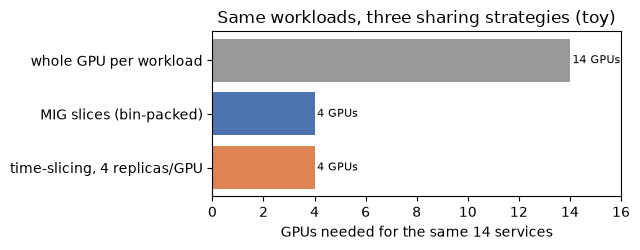

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.barh([r[0] for r in rows], [r[1] for r in rows], color=["#999999", "#4C72B0", "#DD8452"])
for i, r in enumerate(rows):
    ax.text(r[1] + 0.1, i, f"{r[1]} GPUs", va="center", fontsize=8)
ax.set_xlabel("GPUs needed for the same 14 services"); ax.invert_yaxis(); ax.set_xlim(0, 16)
ax.set_title("Same workloads, three sharing strategies (toy)")
plt.tight_layout(); plt.show()

**What to notice.** MIG cuts the GPU count a lot while keeping hard isolation, because most services need only one or two slices. Time-slicing reaches a similar count on paper, but the scheduler cannot see memory or compute, so the result depends on luck: one more model on the same GPU and somebody gets OOM-killed, and every service's latency depends on its neighbours. Use **MIG for production sharing**, **time-slicing for dev**, and **whole GPUs (or several) for big models and training**.

## 3. Dynamic Resource Allocation (DRA)

**What it is.** The classic device plugin model has one big limit: a Pod can only say "give me **N** of `nvidia.com/gpu`". It cannot say "an H100 with at least 40 GB", "two GPUs on the same NVLink domain", or "a MIG slice, or a whole L4 if none is free". **DRA** replaces counting with **claims**: drivers publish detailed device descriptions, and Pods make claims that the scheduler matches with **CEL** expressions. The core of DRA (`resource.k8s.io/v1`) became **GA in Kubernetes 1.34** (its feature gate is locked on from 1.35).

**Simple analogy.** The device plugin is a car park that only tells you "17 spaces free". DRA is a rental desk with a catalogue: "I want an electric car with at least 400 km range, or a hybrid if none is left", and the desk books a specific car for you.

| Object | Written by | What it is |
|---|---|---|
| **ResourceSlice** | the DRA driver (per node or pool) | the catalogue: each device with attributes (model, memory, driver version, NUMA node, NVLink domain ...) |
| **DeviceClass** | cluster admin / driver install | a named category with base selectors, for example `gpu.nvidia.com` |
| **ResourceClaim** | user (or created from a template) | "I need a device from class X matching these CEL rules"; can be shared by several Pods |
| **ResourceClaimTemplate** | user | stamps out one ResourceClaim per Pod (like `volumeClaimTemplates`) |

```yaml
apiVersion: resource.k8s.io/v1
kind: ResourceClaimTemplate
metadata: {name: big-gpu}
spec:
  spec:
    devices:
      requests:
      - name: gpu
        exactly:
          deviceClassName: gpu.nvidia.com
          selectors:
          - cel:
              expression: "device.capacity['gpu.nvidia.com'].memory.compareTo(quantity('40Gi')) >= 0"
---
apiVersion: v1
kind: Pod
metadata: {name: llm}
spec:
  resourceClaims:
  - {name: gpu, resourceClaimTemplateName: big-gpu}
  containers:
  - name: vllm
    image: vllm/vllm-openai:<version>
    resources:
      claims: [{name: gpu}]             # this container uses the claimed device
```

Features that build on DRA, with their status as of Kubernetes 1.37:

| Feature | Status | What it allows |
|---|---|---|
| **Prioritized list** | stable (1.36) | "an H100, else two L40S" |
| **Device taints and tolerations** | stable (1.37) | take a faulty GPU out of service |
| **Extended resources backed by DRA** | stable (1.37) | old-style `nvidia.com/gpu: 1` requests served by a DRA driver, easing migration |
| **Partitionable devices** | beta (1.36) | MIG-like slices described with shared counters and created on demand |
| **Consumable capacity** | beta (1.36) | several claims share one device by amounts |
| ResourceClaims for whole workloads (PodGroups) | beta, off by default (1.37) | one claim for a gang of Pods |

Note that the scheduler does not preempt Pods to free DRA devices yet. On the driver side, NVIDIA donated its **DRA driver for GPUs** to the Kubernetes project in March 2026 (`kubernetes-sigs/dra-driver-nvidia-gpu`); its **ComputeDomains** (multi-node NVLink, for example GB200 NVL72 racks) are officially supported, and plain GPU allocation through it is newer (check its README), while the GPU Operator's `GPUCluster` mode offers whole-GPU and MIG claims. AMD's GPU Operator also has an optional DRA driver, and **DRANET** (a Kubernetes SIG project that started at Google) handles RDMA NICs. The classic device plugin keeps working alongside.

The toy below mimics the matching step: drivers publish slices, claims carry selector functions (standing in for CEL), and an allocator picks devices, honouring a fallback list.

In [5]:
resource_slices = [  # what DRA drivers publish (one entry per device)
    {"node": "n1", "device": "gpu0", "model": "H100", "mem_gb": 80, "nvlink_domain": "A"},
    {"node": "n1", "device": "gpu1", "model": "H100", "mem_gb": 80, "nvlink_domain": "A"},
    {"node": "n2", "device": "gpu0", "model": "L40S", "mem_gb": 48, "nvlink_domain": None},
    {"node": "n2", "device": "gpu1", "model": "L40S", "mem_gb": 48, "nvlink_domain": None},
    {"node": "n3", "device": "gpu0", "model": "L4",   "mem_gb": 24, "nvlink_domain": None},
]
allocated = set()

def allocate(claim_name, alternatives):
    """alternatives: list of (count, selector) tried in order (like DRA 'firstAvailable')."""
    for count, selector, label in alternatives:
        by_node = defaultdict(list)
        for d in resource_slices:
            if (d["node"], d["device"]) not in allocated and selector(d):
                by_node[d["node"]].append(d)
        for node, devs in by_node.items():          # all devices of one claim on one node
            if len(devs) >= count:
                for d in devs[:count]: allocated.add((d["node"], d["device"]))
                return f"{claim_name}: got {count} x {devs[0]['model']} on {node}  ({label})"
    return f"{claim_name}: unschedulable (no alternative fits)"

claims = [
    ("llm-70b",   [(2, lambda d: d["model"] == "H100" and d["nvlink_domain"] is not None, "2 NVLinked H100")]),
    ("llm-13b",   [(1, lambda d: d["mem_gb"] >= 80, "1 x >=80GB"), (2, lambda d: d["mem_gb"] >= 40, "fallback: 2 x >=40GB")]),
    ("embedder",  [(1, lambda d: d["mem_gb"] >= 16, "any >=16GB")]),
    ("llm-70b-2", [(2, lambda d: d["model"] == "H100", "2 x H100")]),
]
for name, alts in claims:
    print(allocate(name, alts))

llm-70b: got 2 x H100 on n1  (2 NVLinked H100)
llm-13b: got 2 x L40S on n2  (fallback: 2 x >=40GB)
embedder: got 1 x L4 on n3  (any >=16GB)
llm-70b-2: unschedulable (no alternative fits)


## 4. Batch and gang scheduling: Kueue, Volcano, KAI Scheduler

**The problem.** A distributed training job with 4 workers is useless until **all 4** run (they wait for each other at the first collective operation). The default scheduler places Pods **one at a time**. With two such jobs and not enough GPUs for both, each job can grab half of what it needs and both wait forever: a **deadlock** that also burns money.

**What it is.** **Gang scheduling** (all-or-nothing) starts a group of Pods only when the whole group fits. **Job queueing** decides *which* job may start, based on quotas, priorities and fairness, before any Pod is created.

**Simple analogy.** A restaurant that seats a party of 4 only when a table for 4 is free, instead of seating two of them now and leaving them waiting at a half-empty table, blocking it for everyone.

| Tool | What it is | Key objects / ideas |
|---|---|---|
| **Kueue** (Kubernetes SIG project) | job **queueing and quota** on top of the default scheduler: admits whole jobs when quota is available, suspends the rest | `ClusterQueue` (quota per resource flavour), `LocalQueue` (per namespace), `ResourceFlavor` (for example "H100 on-demand" vs "spot"), `Workload`, **cohorts** (queues borrow unused quota from each other), fair sharing, preemption, **topology-aware scheduling** (rack/block aware), **MultiKueue** (dispatch to several clusters); works with Jobs, JobSet, LeaderWorkerSet, RayJob/RayCluster, MPIJob, and (alpha) Kubeflow Trainer TrainJob |
| **Volcano** (CNCF incubating) | a full **batch scheduler** replacing the default one for its jobs | `PodGroup` with `minMember` (gang), queues, fair share, HPC-style job plugins |
| **KAI Scheduler** (open-sourced by NVIDIA from Run:ai in 2025; CNCF Sandbox since December 2025; the rest of the Run:ai platform was open-sourced in October 2026) | a GPU-focused scheduler | hierarchical queues and quotas, gang scheduling, GPU sharing (fractions), bin-packing and consolidation |
| **Native gang scheduling** | `Workload` / `PodGroup` APIs inside Kubernetes itself: alpha in 1.35, **beta but off by default in 1.37**, GA planned later | built-in all-or-nothing scheduling, so fewer add-ons will be needed over time |

```yaml
# Kueue: a ClusterQueue with GPU quota, a LocalQueue for a team, and a Job that points to it.
# (the apiVersion depends on your Kueue release; check its docs)
apiVersion: kueue.x-k8s.io/v1beta1
kind: ClusterQueue
metadata: {name: research}
spec:
  cohort: gpu-pool                    # may borrow idle quota from other queues in this cohort
  namespaceSelector: {}
  resourceGroups:
  - coveredResources: ["cpu", "memory", "nvidia.com/gpu"]
    flavors:
    - name: h100
      resources:
      - {name: cpu, nominalQuota: 256}
      - {name: memory, nominalQuota: 2Ti}
      - {name: nvidia.com/gpu, nominalQuota: 16, borrowingLimit: 16}
---
apiVersion: kueue.x-k8s.io/v1beta1
kind: LocalQueue
metadata: {name: team-a, namespace: team-a}
spec: {clusterQueue: research}
---
apiVersion: batch/v1
kind: Job
metadata:
  name: finetune
  namespace: team-a
  labels: {kueue.x-k8s.io/queue-name: team-a}   # Kueue admits it (unsuspends it) when quota allows
spec:
  suspend: true
  parallelism: 4
  completions: 4
  template:
    spec:
      restartPolicy: Never
      containers:
      - name: trainer
        image: registry.example.com/finetune:1.0
        resources: {limits: {nvidia.com/gpu: 2}}
```

The toy shows the deadlock and how gang admission avoids it.

In [6]:
def run(free_gpus, jobs, gang):
    """jobs: name -> (workers, gpus_per_worker, minutes). Pods arrive interleaved (A0, B0, A1, B1, ...)."""
    placed = Counter(); t = 0; log = []; running = {}; done = set()
    queue = [(j, w) for w in range(max(v[0] for v in jobs.values())) for j in jobs if w < jobs[j][0]]
    while len(done) < len(jobs) and t < 300:
        if gang:   # admit whole jobs only
            for j, (w, g, m) in jobs.items():
                if j not in running and j not in done and free_gpus >= w * g:
                    free_gpus -= w * g; running[j] = t + m; log.append(f"t={t:>3} admit {j} ({w}x{g} GPUs)")
        else:      # place pods one by one, as they arrive
            for j, w in list(queue):
                g = jobs[j][1]
                if free_gpus >= g:
                    free_gpus -= g; placed[j] += 1; queue.remove((j, w))
            for j, (w, g, m) in jobs.items():
                if j not in running and j not in done and placed[j] == w:
                    running[j] = t + m; log.append(f"t={t:>3} all {w} pods of {j} running -> training starts")
        for j, end in list(running.items()):
            if end <= t:
                free_gpus += jobs[j][0] * jobs[j][1]; del running[j]; done.add(j)
                log.append(f"t={t:>3} {j} finished, GPUs freed")
        t += 1
    if len(done) < len(jobs):
        log.append(f"t={t:>3} STUCK: pods placed per job {dict(placed)}, free GPUs {free_gpus} -> deadlock")
    return log

jobs = {"job-A": (4, 1, 30), "job-B": (4, 1, 30)}       # each needs 4 GPUs; we have 6
print("Default scheduler (pod by pod):")
for line in run(6, jobs, gang=False): print("  ", line)
print("\nGang admission (Kueue / Volcano / KAI style):")
for line in run(6, jobs, gang=True): print("  ", line)

Default scheduler (pod by pod):
   t=300 STUCK: pods placed per job {'job-A': 3, 'job-B': 3}, free GPUs 0 -> deadlock

Gang admission (Kueue / Volcano / KAI style):
   t=  0 admit job-A (4x1 GPUs)
   t= 30 job-A finished, GPUs freed
   t= 31 admit job-B (4x1 GPUs)
   t= 61 job-B finished, GPUs freed


## 5. AMD GPUs and ROCm

**What it is.** **ROCm** is AMD's open-source GPU software stack, the counterpart of CUDA (HIP is its CUDA-like programming layer). In August 2026 AMD jumped from ROCm 7.x straight to **ROCm 10** (now branded the "ROCm Core SDK", with a faster release cadence), so do not be surprised that there is no ROCm 8 or 9. AMD's data-centre **Instinct** GPUs (MI300X, MI325X, MI350X/MI355X) have very large memory per GPU, which suits big LLMs. PyTorch, vLLM and SGLang ship ROCm builds.

On Kubernetes the pattern mirrors NVIDIA: the **AMD GPU Operator** installs the driver (through Kernel Module Management), the **device plugin** (resource name `amd.com/gpu`) or an optional **DRA driver**, a node labeller, a device metrics exporter and a test runner. Images must be ROCm builds (for example `rocm/vllm`), not CUDA builds.

**When to use / not.** Consider AMD for large-memory inference and when supply or cost is better; check that your exact kernels, quantization formats and serving framework versions are supported on ROCm, and test throughput yourself. Mixing vendors in one cluster is fine: label and taint each pool, and request the right resource name.

```yaml
resources:
  limits: {amd.com/gpu: 1}
nodeSelector: {amd.com/gpu.product-name: <product label from the node labeller>}
```

## 6. LLM serving stacks on Kubernetes

**The layers.** It helps to separate four layers, because products mix them:

1. **Inference engine**: runs the model on the GPU, does continuous batching and KV-cache management (vLLM, SGLang, TensorRT-LLM, TGI, llama.cpp). Covered in [inference optimization](../../08_LLM/13_inference_optimization.ipynb).
2. **Model server / runtime wrapper**: an HTTP/gRPC API (often OpenAI-compatible), health checks, metrics.
3. **Orchestration on Kubernetes**: CRDs/operators that create the Deployments, autoscaling, rollouts, multi-node and prefill/decode layouts.
4. **Routing / gateway**: picks the right replica for each request (load-, prefix- and KV-cache-aware), plus auth and rate limits.

```mermaid
flowchart LR
  C[clients] --> G[Gateway API + Inference Extension<br/>InferencePool, endpoint picker]
  G -->|KV/prefix-aware pick| P1[vLLM / SGLang replica 1]
  G --> P2[replica 2]
  G --> P3[replica 3]
  subgraph Disaggregated[optional: prefill/decode split]
    PF[prefill workers] -->|KV cache transfer, NIXL / RDMA| DC[decode workers]
  end
  G -.-> PF
  O[operator: KServe / llm-d / Dynamo / KubeRay] -->|creates & scales| P1
  O --> P2
  O --> P3
  M[Prometheus: queue depth, KV-cache use] --> A[KEDA / HPA / planner] --> O
```

| Stack | What it is (late 2026) | Pick it when |
|---|---|---|
| **NVIDIA Dynamo-Triton** (formerly Triton Inference Server; renamed in 2025 as part of the Dynamo platform) | a general multi-framework server (TensorRT, ONNX, PyTorch, Python, TensorRT-LLM backends), dynamic batching, ensembles | many non-LLM models (vision, tabular, ASR) or mixed fleets on NVIDIA |
| **KServe** (CNCF incubating since 2025; v0.21 in late 2026) | the Kubernetes-native model serving platform: `InferenceService` for predictive and generative models, plus `LLMInferenceService` (still a pre-v1 API) built on **llm-d** for distributed LLM serving, with KEDA scaling | you want one platform API for all models, with autoscaling and canaries |
| **vLLM production stack** (vllm-project) | a Helm chart (`vllm/vllm-stack`) reference stack: vLLM engines + a request router (round-robin and session-sticky routing) + Prometheus/Grafana + LMCache KV offload | simple path from one vLLM to a small production cluster |
| **llm-d** (CNCF Sandbox since March 2026; v1.0 in October 2026; started by Red Hat, Google Cloud, IBM Research, CoreWeave and NVIDIA) | Kubernetes-native distributed inference on vLLM (and SGLang): the **llm-d Router** (the reference endpoint picker for the Gateway API Inference Extension) with KV-cache- and load-aware routing, **prefill/decode disaggregation** (`DisaggregatedSet` on LeaderWorkerSet), wide expert-parallelism, tiered KV cache, priority/QoS, SLO-aware autoscaling; published as "well-lit path" guides | large-scale serving where routing and disaggregation matter |
| **NVIDIA Dynamo** (1.0 announced March 2026) | an open-source distributed inference framework over vLLM, SGLang and TensorRT-LLM: OpenAI-compatible frontend, KV-aware router, **Planner** (SLA-driven autoscaling of prefill and decode pools), **NIXL** transfer library, **KVBM** (KV block manager offloading to CPU/SSD), **Grove** (topology-aware gang scheduling); a Kubernetes operator deploys a `DynamoGraphDeployment` | NVIDIA fleets that want an integrated disaggregated stack |
| **NVIDIA NIM** | prebuilt, optimized inference microservice containers for specific models (LLMs, embedding, reranking, speech ...) with an OpenAI-compatible API, part of NVIDIA AI Enterprise; the **NIM Operator** adds `NIMCache` (pre-pull weights to shared storage) and `NIMService` (Deployment + autoscaling + monitoring) | you want a supported, pre-tuned container instead of building your own |
| **Ray Serve on KubeRay** | Ray's model-serving library; **KubeRay** operator provides `RayCluster`, `RayJob`, `RayService` CRDs | Python-heavy pipelines, multi-model composition, Ray already used for data/training |
| **SGLang** | a fast inference engine (RadixAttention prefix cache, structured output) for NVIDIA, AMD, TPUs and more; runs under llm-d, Dynamo, Ray Serve or its own Kubernetes tooling (the **OME** operator and **RoleBasedGroup** for router/prefill/decode roles) | heavy prefix reuse, agents, structured generation |
| **AIBrix** (vllm-project), KubeAI | other open-source vLLM-on-Kubernetes control planes (prefix/load-aware gateway routing, multi-LoRA, autoscaling on engine metrics); KubeAI is smaller and less actively maintained now | worth a look when comparing options |

```yaml
# KServe: an LLM with the Hugging Face runtime (vLLM backend), scaled on load.
apiVersion: serving.kserve.io/v1beta1
kind: InferenceService
metadata: {name: qwen-chat}
spec:
  predictor:
    minReplicas: 1
    maxReplicas: 4
    model:
      modelFormat: {name: huggingface}
      args: ["--model_name=qwen-chat", "--model_id=Qwen/Qwen2.5-7B-Instruct"]
      resources:
        limits: {nvidia.com/gpu: "1", memory: 32Gi}
```

```yaml
# KubeRay: a RayService (Ray Serve app on an auto-managed Ray cluster), shortened.
apiVersion: ray.io/v1
kind: RayService
metadata: {name: rag-serve}
spec:
  serveConfigV2: |
    applications:
    - name: rag
      import_path: app:deployment
      runtime_env: {working_dir: "https://example.com/app.zip"}
  rayClusterConfig:
    headGroupSpec: {rayStartParams: {}, template: {spec: {containers: [{name: ray-head, image: rayproject/ray:<version>}]}}}
    workerGroupSpecs:
    - groupName: gpu
      replicas: 2
      rayStartParams: {}
      template: {spec: {containers: [{name: ray-worker, image: rayproject/ray:<version>-gpu,
                                      resources: {limits: {nvidia.com/gpu: 1}}}]}}
```

**How to choose (rule of thumb).** One or two models, small team: vLLM (or SGLang) Deployment + HPA/KEDA, or the vLLM production stack. Many models and teams, one platform: KServe. Very large models, high traffic, cost pressure: llm-d or Dynamo with KV-aware routing and disaggregation. Want vendor support and pre-tuned containers: NIM. Python pipelines: Ray Serve.

## 7. Gateway API Inference Extension and KV-cache-aware routing

**What it is.** A normal load balancer spreads requests evenly. For LLMs that is wasteful: if replica 2 already has the KV cache for a long system prompt or an ongoing conversation, sending the next turn there skips most of the **prefill** work (see [LLM caching](../../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb)). The **Gateway API Inference Extension** adds this intelligence to any compatible gateway:

- **InferencePool**: a group of model-server Pods (like a Service, but for inference) plus a pointer to an **Endpoint Picker (EPP)**.
- **Endpoint Picker (EPP)**: a component the gateway asks (through Envoy's external-processing hook) "which Pod should take this request?". It looks at live metrics (queue length, KV-cache use, loaded LoRA adapters, prefix-cache hits) and answers. Since the extension's v1.6 (August 2026) the full EPP lives in the **llm-d** project as the **llm-d Router**; the extension itself keeps the stable `InferencePool` API and a minimal reference picker.
- **InferenceObjective** (earlier called InferenceModel): per-workload priority, so less important traffic is shed first under load. It moved out of the extension and is now served by llm-d (`llm-d.ai/v1`).

InferencePool is GA (`inference.networking.k8s.io/v1`). Gateways listed as conformant include Istio, Agentgateway, NGINX Gateway Fabric, Alibaba Cloud ACK Gateway and Higress; Envoy Gateway, kgateway and GKE Gateway also support it, and Google's managed **GKE Inference Gateway** (GA) is now "powered by llm-d".

**Simple analogy.** A hospital receptionist who sends you back to the doctor who already has your file open, unless that doctor has a long queue.

```yaml
apiVersion: inference.networking.k8s.io/v1
kind: InferencePool
metadata: {name: qwen-pool}
spec:
  selector: {matchLabels: {app: vllm-qwen}}     # the model-server Pods
  targetPorts: [{number: 8000}]
  endpointPickerRef: {name: qwen-epp, port: {number: 9002}}
---
apiVersion: gateway.networking.k8s.io/v1
kind: HTTPRoute
metadata: {name: llm}
spec:
  parentRefs: [{name: inference-gateway}]
  rules:
  - matches: [{path: {type: PathPrefix, value: /v1/}}]
    backendRefs: [{group: inference.networking.k8s.io, kind: InferencePool, name: qwen-pool}]
```

### Runnable toy: round-robin vs least-loaded vs prefix/KV-aware routing

200 users, each in a conversation with a long shared prefix (system prompt + history). 4 replicas, each with an LRU KV cache that can hold a limited number of prefixes. Time to first token (TTFT) is modelled as queue wait + prefill time for the **uncached** tokens. All costs are illustrative.

In [7]:
class Replica:
    def __init__(self, cache_slots):
        self.cache = OrderedDict(); self.slots = cache_slots; self.busy_until = 0.0
    def cached_tokens(self, prefix_id, prefix_len):
        return prefix_len if prefix_id in self.cache else 0
    def touch(self, prefix_id):
        self.cache[prefix_id] = True; self.cache.move_to_end(prefix_id)
        if len(self.cache) > self.slots: self.cache.popitem(last=False)   # evict least recently used

def simulate_routing(policy, n_replicas=4, n_users=200, n_requests=4000, cache_slots=60,
                     prefix_len=3000, new_tokens=200, prefill_tok_per_s=40000, rate_per_s=60, seed=SEED):
    rng = random.Random(seed)
    reps = [Replica(cache_slots) for _ in range(n_replicas)]
    t, rr, ttfts, hits = 0.0, 0, [], 0
    weights = [1 / (i + 1) ** 0.8 for i in range(n_users)]            # some users are much more active
    for _ in range(n_requests):
        t += rng.expovariate(rate_per_s)
        user = rng.choices(range(n_users), weights=weights)[0]
        if policy == "round-robin":
            r = reps[rr % n_replicas]; rr += 1
        elif policy == "least-loaded":
            r = min(reps, key=lambda x: x.busy_until)
        else:  # prefix/KV-aware: prefer a cache hit unless that replica is much busier
            def score(x):
                wait = max(0.0, x.busy_until - t)
                saved = x.cached_tokens(user, prefix_len) / prefill_tok_per_s
                return wait - saved
            r = min(reps, key=score)
        cached = r.cached_tokens(user, prefix_len); hits += cached > 0
        work = (prefix_len - cached + new_tokens) / prefill_tok_per_s   # prefill seconds
        start = max(t, r.busy_until); r.busy_until = start + work
        ttfts.append(r.busy_until - t)
        r.touch(user)
    a = np.array(ttfts) * 1000
    return {"policy": policy, "cache hit rate": hits / n_requests,
            "mean TTFT ms": a.mean(), "p95 TTFT ms": np.percentile(a, 95)}

res = pd.DataFrame([simulate_routing(p) for p in ["round-robin", "least-loaded", "prefix/KV-aware"]])
print(res.to_string(index=False, formatters={"cache hit rate": "{:.0%}".format,
                                             "mean TTFT ms": "{:.0f}".format, "p95 TTFT ms": "{:.0f}".format}))

         policy cache hit rate mean TTFT ms p95 TTFT ms
    round-robin            57%           65         176
   least-loaded            56%           50         133
prefix/KV-aware            92%           14          80


**What to notice.** Round-robin and least-loaded scatter each user's turns across replicas, so every replica must hold every hot prefix and the caches thrash. KV-aware routing keeps a user "sticky" to the replica holding their prefix, so most requests skip the long prefill, which lowers both the average and the tail latency. The `score` function balances cache affinity against queue wait, which is exactly what real endpoint pickers do with more signals (llm-d's scheduler, Dynamo's KV router, the vLLM production-stack router). Change `cache_slots` or `rate_per_s` to see when affinity stops paying off.

## 8. Autoscaling LLM servers

**Why CPU/GPU utilisation fails.** A vLLM server keeps the GPU busy and pre-allocates most GPU memory for the KV cache, so "GPU util 95%" and "memory 90%" are normal at light and heavy load alike. The signals that move *before* users suffer are:

| Signal (vLLM metric names) | Meaning | Use |
|---|---|---|
| `vllm:num_requests_waiting` | requests queued, not yet running | primary scale-up signal |
| `vllm:num_requests_running` | requests in the current batch | concurrency per replica |
| `vllm:kv_cache_usage_perc` (0-1; older engine versions called it `gpu_cache_usage_perc`) | how full the KV cache is | near 1.0 means preemptions and recompute soon |
| `vllm:time_to_first_token_seconds`, `vllm:inter_token_latency_seconds`, `vllm:request_queue_time_seconds` (histograms) | what users feel | SLO checks, planner-style autoscaling |
| `vllm:prefix_cache_hits` / `vllm:prefix_cache_queries` | prefix-cache hit rate | is routing keeping users sticky? |

**How.** Export these with Prometheus, then scale with **KEDA** (Prometheus scaler) or an **HPA** on custom metrics through a metrics adapter; llm-d and Dynamo ship their own SLO-aware autoscalers ("planner"). Keep `minReplicas >= 1` for user-facing models unless a cold start is acceptable.

```yaml
apiVersion: keda.sh/v1alpha1
kind: ScaledObject
metadata: {name: vllm-qwen}
spec:
  scaleTargetRef: {name: vllm-qwen}
  minReplicaCount: 1
  maxReplicaCount: 8
  cooldownPeriod: 600                       # GPUs are slow to come back; scale down slowly
  triggers:
  - type: prometheus
    metadata:
      serverAddress: http://prometheus.monitoring:9090
      query: sum(vllm:num_requests_waiting{model_name="qwen"})
      threshold: "5"                        # aim for about 5 waiting requests per replica
```

### Runnable toy: queue-depth autoscaler with cold starts

One LLM service, traffic with a burst. Each replica serves up to 16 concurrent requests, each taking about 4 s. A new replica needs a **cold start** (node + image + weights) before it serves. We compare a utilisation-based autoscaler (it sees "busy" only when replicas are already saturated) with a queue-depth autoscaler, and two cold-start times. Illustrative numbers.

In [8]:
def llm_autoscale(policy, cold_start_s, horizon_s=1800, dt=5, conc=16, svc_s=4.0, max_rep=10, seed=SEED):
    rng = np.random.default_rng(seed)
    times = np.arange(0, horizon_s, dt)
    rate = 6 + 22 * ((times > 400) & (times < 1100)) + 10 * np.exp(-((times - 1400) / 120.0) ** 2)  # req/s
    ready, starting = 2, []                 # warm minimum of 2; starting = times new replicas become ready
    queue, rows, last_up = 0.0, [], -1e9
    for i, t in enumerate(times):
        ready += sum(1 for s in starting if s <= t); starting = [s for s in starting if s > t]
        arrivals = rng.poisson(rate[i] * dt)
        capacity = ready * conc / svc_s * dt                       # requests we can finish this step
        queue = max(0.0, queue + arrivals - capacity)
        in_flight = rate[i] * svc_s + queue                         # running (Little's law) + waiting
        total = ready + len(starting)
        if policy == "utilisation":
            # a saturating signal: it can never read above 100%, so it grows at most 1/0.8 = 1.25x per decision
            util = min(1.0, in_flight / (ready * conc))
            want = math.ceil(ready * util / 0.8)
        else:
            # queue-depth style: running + waiting requests, target 12 of the 16 slots per replica
            want = math.ceil(in_flight / 12)
        want = min(max_rep, max(2, want))
        if want > total and t - last_up >= 30:                      # add replicas (30 s between decisions)
            starting += [t + cold_start_s] * (want - total); last_up = t
        elif want < ready and not starting and queue == 0 and i % 24 == 0:   # scale down slowly (every 2 min)
            ready -= 1
        wait_s = queue / max(ready * conc / svc_s, 1e-9)           # rough queueing delay
        rows.append((t, rate[i], ready, queue, wait_s))
    df = pd.DataFrame(rows, columns=["t", "rate", "ready", "queue", "wait_s"])
    return df

summ, runs = [], {}
for policy in ["utilisation", "queue-depth"]:
    for cold in [90, 480]:
        d = llm_autoscale(policy, cold); runs[(policy, cold)] = d
        summ.append({"policy": policy, "cold start": f"{cold} s", "p95 wait s": np.percentile(d.wait_s, 95),
                     "% time wait > 10 s": (d.wait_s > 10).mean(), "GPU-replica-hours": d.ready.sum() * 5 / 3600})
print(pd.DataFrame(summ).to_string(index=False, formatters={"p95 wait s": "{:.1f}".format,
      "% time wait > 10 s": "{:.0%}".format, "GPU-replica-hours": "{:.1f}".format}))

     policy cold start p95 wait s % time wait > 10 s GPU-replica-hours
utilisation       90 s      240.1                42%               2.9
utilisation      480 s      885.8                78%               1.6
queue-depth       90 s       48.6                13%               3.4
queue-depth      480 s      586.2                48%               2.8


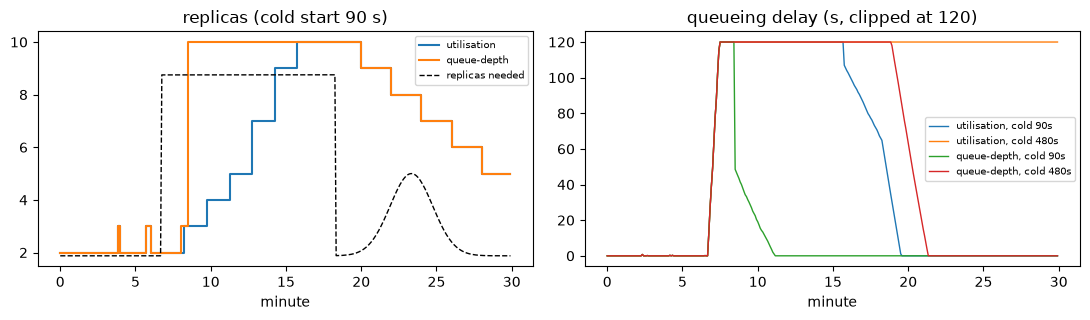

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3), sharey=False)
for (policy, cold), d in runs.items():
    if cold == 90: ax[0].step(d.t / 60, d.ready, where="post", label=f"{policy}")
    ax[1].plot(d.t / 60, d.wait_s.clip(upper=120), label=f"{policy}, cold {cold}s", lw=1)
base = runs[("queue-depth", 90)]
ax[0].plot(base.t / 60, base.rate * 4.0 / 16 / 0.8, "k--", lw=1, label="replicas needed")
ax[0].set_title("replicas (cold start 90 s)"); ax[0].set_xlabel("minute"); ax[0].legend(fontsize=7)
ax[1].set_title("queueing delay (s, clipped at 120)"); ax[1].set_xlabel("minute"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**What to notice.** The utilisation signal saturates at 100%, so it under-reacts to a burst and climbs in small steps; the queue-depth (running + waiting) signal sees the whole backlog and asks for the right number at once. A long **cold start** hurts every policy, which is why cold-start time (next section) is as important as the scaling rule. Practical patterns: keep a warm minimum, pre-pull images onto GPU nodes, cache weights on the node, scale up fast and down slowly, and for bursty internal workloads accept scale-to-zero with a queue in front.

## 9. Model loading and caching

**The problem.** A 70B model in 16-bit is about 140 GB of weights. Before a replica serves, it must: get a node (minutes for a GPU VM), pull the image (CUDA images are often 10-20 GB), fetch the weights, and load them into GPU memory. That total is your **cold start**.

| Option | How | Pros | Cons |
|---|---|---|---|
| Bake weights into the image | `COPY` the model into the image | one artifact, versioned together | huge images, slow pulls, rebuild per model; registries struggle |
| Weights on a shared PVC (RWX file system, for example EFS/Azure Files/Filestore/Lustre) | mount read-only | no download per Pod | shared file system throughput can be the bottleneck |
| Download from object storage at start (init container) | S3/GCS/Blob/Hugging Face -> `emptyDir` | simple, flexible | every replica re-downloads |
| **Stream from object storage** into GPU memory | for example the **Run:ai Model Streamer** (`vllm serve s3://... --load-format runai_streamer`, safetensors only), Dynamo ModelExpress | parallel reads, starts loading while downloading | needs fast network and support in the engine |
| Node-local cache (NVMe), pre-warmed | DaemonSet / `NIMCache` / KServe local model cache / **Fluid** (CNCF incubating dataset cache) | very fast repeat starts | cache management; first start still slow |
| **Model as an OCI artifact / image volume** | KServe **Modelcars** (`storageUri: oci://...`, opt-in), Kubernetes **image volumes** (stable in 1.36) mount an OCI image/artifact as a read-only volume | reuse registry tooling, signing, node image cache | needs recent Kubernetes / runtime support |

Also: use **safetensors** (fast, safe, memory-mappable) rather than pickle checkpoints; quantized weights (FP8, INT4) are smaller to move; and a **startupProbe** must allow for the load time (see the deep-dive notebook).

The toy below adds up an illustrative cold-start budget for one replica of a 140 GB model.

In [10]:
MODEL_GB = 140
def cold_start(node_s, image_gb, image_gbps, weights_gbps, load_gbps, overlap=False):
    pull = image_gb * 8 / image_gbps                     # GB -> Gbit / (Gbit/s)
    fetch = MODEL_GB * 8 / weights_gbps if weights_gbps else 0
    load = MODEL_GB * 8 / load_gbps
    body = max(fetch, load) if overlap else fetch + load    # streaming overlaps download and load
    return node_s, pull, body, node_s + pull + body

options = {   # illustrative throughputs in Gbit/s
    "baked into image (image 155 GB)":       cold_start(150, 155, 10, 0, 40),
    "download from object store at start":   cold_start(150, 15, 10, 10, 40),
    "shared file system PVC":                cold_start(150, 15, 10, 8, 40),
    "streamed from object store":            cold_start(150, 15, 10, 25, 40, overlap=True),
    "warm node: image cached + local NVMe":  cold_start(0, 0, 10, 0, 40),
}
df = pd.DataFrame(options, index=["node ready s", "image pull s", "weights s", "total s"]).T.round(0)
df["total min"] = (df["total s"] / 60).round(1)
print(df.to_string())

                                      node ready s  image pull s  weights s  total s  total min
baked into image (image 155 GB)              150.0         124.0       28.0    302.0        5.0
download from object store at start          150.0          12.0      140.0    302.0        5.0
shared file system PVC                       150.0          12.0      168.0    330.0        5.5
streamed from object store                   150.0          12.0       45.0    207.0        3.4
warm node: image cached + local NVMe           0.0           0.0       28.0     28.0        0.5


## 10. Multi-node training on Kubernetes vs Slurm

**What it is.** Training big models needs many GPUs across many nodes working as one job (see [distributed training](../../05_Deep_Learning/11_distributed_training.ipynb) for DDP, FSDP, tensor and pipeline parallelism). On Kubernetes, that job is described by:

| Object | Project | What it does |
|---|---|---|
| **TrainJob** + `TrainingRuntime` / `ClusterTrainingRuntime` | **Kubeflow Trainer** (v2; APIs still `v1alpha1`) | one job API for PyTorch, DeepSpeed, Megatron-LM, JAX, MLX, XGBoost ...; platform teams write runtimes, data scientists submit short TrainJobs (or use the Kubeflow Python SDK); built on JobSet. It replaces the Training Operator v1 kinds (`PyTorchJob`, `TFJob`, `MPIJob`), now in maintenance mode, which you will still see in older docs |
| **JobSet** | Kubernetes SIG project | a group of Jobs that run as one unit (for example 1 launcher + N workers), with stable DNS between them and failure policies |
| **LeaderWorkerSet (LWS)** | Kubernetes SIG project | groups of Pods (1 leader + workers) as one replica; used for **multi-node inference** of huge models |
| **RayJob** | KubeRay | Ray-based training and data processing |

Add Kueue (section 4) for queueing and gang admission, and topology-aware placement so workers sit close together in the network.

```yaml
apiVersion: trainer.kubeflow.org/v1alpha1
kind: TrainJob
metadata: {name: llama-finetune, labels: {kueue.x-k8s.io/queue-name: team-a}}
spec:
  runtimeRef: {name: torch-distributed}          # a ClusterTrainingRuntime provided by the platform
  trainer:
    image: registry.example.com/finetune:1.2
    command: ["torchrun", "train.py", "--config", "configs/llama-8b.yaml"]
    numNodes: 4
    resourcesPerNode:
      limits: {nvidia.com/gpu: 8}
```

**Slurm** is the classic HPC batch scheduler used by most supercomputers and many AI labs.

| | Slurm | Kubernetes (+ Kueue/Volcano/KAI, Trainer, JobSet) |
|---|---|---|
| Native strength | batch jobs, gang allocation, partitions, fair-share, QoS, preemption, topology-aware placement | long-running services (inference, APIs), self-healing, rolling updates, huge ecosystem |
| User interface | `sbatch`, `srun`, `squeue`; researchers like it | YAML / Python SDKs; platform teams like it |
| Containers | optional (Enroot/Pyxis, Apptainer) | everything is a container |
| Where it fits | dedicated training clusters | mixed training + inference platforms, cloud |

They are converging: **Slinky** (SchedMD's projects for running Slurm on Kubernetes; its `slurm-operator` runs Slurm compute and login nodes as Pods) and **CoreWeave SUNK** (Slurm on Kubernetes) let one GPU pool serve both Slurm users and Kubernetes services. NVIDIA acquired SchedMD, the company behind Slurm, in December 2025; Slurm remains open source.

## 11. GPU networking concepts

**Why it matters.** In multi-GPU work, GPUs constantly exchange data (gradients in training, activations in tensor parallelism, KV cache in disaggregated inference). The network often limits speed more than the GPUs do.

| Technology | Scope | One line |
|---|---|---|
| **NVLink / NVSwitch** | GPUs inside one server (or one rack) | very high-bandwidth GPU-to-GPU links ("scale-up"); **NVL72** systems (GB200/GB300) join 72 GPUs and 36 Grace CPUs into one NVLink domain across a liquid-cooled rack; on Kubernetes, multi-node NVLink is set up with the NVIDIA DRA driver's ComputeDomains |
| **PCIe** | inside a server | the general bus; much slower than NVLink for GPU-to-GPU |
| **InfiniBand** | between servers | low-latency, high-bandwidth HPC network with RDMA built in |
| **RoCE** (RDMA over Converged Ethernet) | between servers | RDMA on Ethernet (for example NVIDIA Spectrum-X, many clouds) |
| **RDMA / GPUDirect RDMA** | between servers | the NIC reads/writes GPU memory directly, skipping the CPU and extra copies |
| **AWS EFA** (Elastic Fabric Adapter) | between instances on AWS | AWS's OS-bypass network (SRD protocol via libfabric) for HPC/ML; supports NCCL, NIXL and MPI and GPUDirect RDMA on GPU instances; stays inside one availability zone |
| **NCCL** (RCCL on AMD) | software | the collective-communication library (all-reduce, all-gather ...) that frameworks call |

On Kubernetes, extra NICs reach Pods through **Multus** (several network interfaces per Pod), the RDMA shared and **SR-IOV** device plugins, or DRA network drivers (DRANET, the Network Operator's DRA SR-IOV driver). The **NVIDIA Network Operator** installs the drivers (DOCA-OFED), these plugins, secondary CNIs and IP address management.

The toy estimates one **ring all-reduce** of a 7B model's gradients (bf16, about 14 GB) with the standard formula time = 2 (N-1)/N x size / bandwidth. Bandwidths are rough, illustrative per-GPU figures.

In [11]:
def ring_allreduce_s(size_gb, n_gpus, gbytes_per_s):
    return 2 * (n_gpus - 1) / n_gpus * size_gb / gbytes_per_s

links = {"NVLink (in-node)": 400, "InfiniBand / RoCE, 400 Gb/s per GPU": 50,
         "Ethernet 100 Gb/s, no RDMA": 10, "PCIe only (no NVLink)": 25}
size = 14.0
rows = [(name, bw, ring_allreduce_s(size, 8, bw)) for name, bw in links.items()]
print(pd.DataFrame(rows, columns=["link", "GB/s per GPU (illustrative)", "all-reduce seconds (8 GPUs)"])
      .round(2).to_string(index=False))
print("\nIf one training step computes for ~1 s, a 2.4 s all-reduce means the GPUs mostly wait.")
print("That is why overlap of compute and communication, gradient compression and good networks matter.")

                               link  GB/s per GPU (illustrative)  all-reduce seconds (8 GPUs)
                   NVLink (in-node)                          400                         0.06
InfiniBand / RoCE, 400 Gb/s per GPU                           50                         0.49
         Ethernet 100 Gb/s, no RDMA                           10                         2.45
              PCIe only (no NVLink)                           25                         0.98

If one training step computes for ~1 s, a 2.4 s all-reduce means the GPUs mostly wait.
That is why overlap of compute and communication, gradient compression and good networks matter.


## 12. GPU clouds, neoclouds and serverless GPUs

Beyond AWS, Azure and Google Cloud, a group of GPU-focused clouds (**neoclouds**) and serverless GPU platforms became major sources of capacity. One line each (as of late 2026; offerings change often, check their sites):

| Provider | What it offers |
|---|---|
| **CoreWeave** | a Kubernetes-native GPU cloud: managed bare-metal Kubernetes (CKS) and Slurm on Kubernetes (SUNK) on the same clusters; listed on the stock market since March 2025, and it completed the acquisition of Weights & Biases in May 2025 |
| **Lambda** | GPU cloud: on-demand instances, multi-node "1-Click Clusters" and large reserved "Superclusters" for training and inference (site moved to lambda.com) |
| **Crusoe** | an AI cloud built around energy-first data centres: NVIDIA and AMD GPU VMs, managed Kubernetes, managed Slurm, managed inference |
| **Nebius** | a full-stack AI cloud: GPU compute, managed Kubernetes, Slurm clusters, and Token Factory for managed inference |
| **Runpod** | persistent GPU "Pods", serverless autoscaling inference endpoints, and multi-GPU clusters; popular with individuals and startups |
| **Modal** | serverless Python: decorate a function and it runs on GPUs that autoscale (including to zero), plus sandboxes for running agent code |
| Together AI, Fireworks, Baseten, Replicate | hosted inference APIs / platforms for open models (plus fine-tuning, dedicated endpoints) |

**When to use which.** Hyperscalers: integration with the rest of your stack, compliance, reserved capacity. Neoclouds: large GPU clusters, often newer GPUs sooner, Kubernetes/Slurm close to bare metal. Serverless GPUs: spiky or small workloads where scale-to-zero beats paying for idle GPUs, accepting cold starts. Watch **capacity** (reservations, quotas), **egress** costs for moving data, and **portability** (plain Kubernetes + containers keep you mobile).

## 13. On-prem, air-gapped, hybrid and multi-cloud AI

**On-prem / air-gapped** (no internet, common in defence, healthcare, finance):
- mirror everything: container images (Harbor, Quay, a registry mirror), Helm charts, model weights, Python wheels, OS packages; the GPU Operator and NIM support air-gapped installs with a private registry;
- sign and scan images before they enter (supply chain, see the deep-dive notebook);
- plan for **driver and firmware lifecycle**, spare capacity and power/cooling yourself;
- typical stacks: OpenShift (+ OpenShift AI), Rancher/RKE2, vanilla kubeadm, NVIDIA AI Enterprise, plus vLLM/KServe.

**Hybrid and multi-cloud** (training on-prem or on a neocloud, serving in a hyperscaler, or several clouds for capacity):
- keep the **workload definition portable**: containers, Helm/Kustomize, KServe/llm-d CRDs, GitOps (Argo CD / Flux) pushing the same manifests everywhere;
- move **weights, not data**, where possible (data residency); use object storage replication for model artifacts;
- unify identity and policy (OIDC, workload identity, Kyverno/Gatekeeper policies), and observability (Prometheus/OpenTelemetry);
- multi-cluster tools: Cluster API for lifecycle, Rancher/OpenShift ACM/Azure Arc/GKE fleets for management, Kueue's **MultiKueue** to dispatch batch jobs to several clusters;
- an **LLM gateway** (LiteLLM, Envoy AI Gateway, Kong AI Gateway, cloud gateways) in front can route between self-hosted models and hosted APIs by cost, latency or data class.

## 14. CNCF Kubernetes AI Conformance

**What it is.** A CNCF program (beta in mid-2025, v1.0 launched on 11 November 2025) that certifies **Kubernetes platforms** (not people) as able to run AI/ML workloads reliably and portably, the same way the older Certified Kubernetes program certifies API conformance. Requirements are published per Kubernetes minor version (checklists exist up to 1.37), each with an ID (for example KAR-11), and start as SHOULD before becoming MUST. Vendors submit evidence and recertify yearly. By March 2026, 31 platforms were certified (the first ones named included Amazon EKS, Google GKE and VMware vSphere Kubernetes Service).

**Requirement areas** (simplified):
1. **DRA** support for accelerators;
2. **Gateway API** for inference traffic (advanced inference ingress);
3. **gang scheduling** through at least one solution (Kueue, Volcano, ...);
4. **cluster autoscaling** of accelerator nodes;
5. **HPA** on custom metrics for accelerator Pods;
6. an accelerator **performance metrics** endpoint and standard AI service monitoring;
7. at least one complex **AI operator** (CRD-based, for example KubeRay or Kubeflow Trainer) works reliably;
8. newer items added for 1.35: high-performance Pod-to-Pod communication and **disaggregated inference** support.

For a platform buyer, the conformance list is a quick way to see which managed services and distributions have done this homework.

## 15. Container runtimes and build tooling

**What it is.** "Docker" is several separate pieces. Kubernetes uses only the runtime part.

| Piece | What it is | Notes |
|---|---|---|
| **OCI specs** | open standards for image format, runtime behaviour and registry distribution | why images built by any tool run anywhere |
| **runc** (and **crun**, **youki**) | low-level runtime: actually creates the container (namespaces, cgroups) from an OCI bundle | crun is a fast C implementation, youki is in Rust |
| **containerd** (2.x; 2.3 is the long-term-support line) | a high-level runtime daemon: pulls images, manages containers, implements the Kubernetes **CRI** | the default on most managed Kubernetes; Docker Engine also uses it underneath |
| **CRI-O** | a lightweight CRI runtime made only for Kubernetes; its versions follow Kubernetes minors (1.37 ...) | default in OpenShift |
| **dockershim** | the old adapter that let kubelet use Docker Engine | removed in Kubernetes 1.24; images built with Docker still run fine |
| **gVisor, Kata Containers** | sandboxed runtimes (user-space kernel / lightweight VMs), selected with a `RuntimeClass` | for untrusted code, for example code written by AI agents |
| **NVIDIA Container Toolkit + CDI** | makes GPUs visible to containers; CDI names devices like `nvidia.com/gpu=all` or `nvidia.com/gpu=0` (spec generated with `nvidia-ctk cdi generate`) | installed by the GPU Operator; Docker (25+), Podman, containerd and CRI-O understand CDI |

**Building images:**

| Tool | What it is | When |
|---|---|---|
| **Docker Engine + BuildKit** | the default builder in modern Docker: parallel stages, cache mounts, secrets at build time | everyday builds |
| **docker buildx** | the CLI front-end to BuildKit; builds **multi-architecture** images (`linux/amd64` + `linux/arm64`) into one image index, by QEMU emulation, native builder nodes per architecture, or cross-compiling; remote/cache backends | ARM nodes (AWS Graviton, Ampere, Apple silicon laptops, NVIDIA Grace) next to x86 |
| **Podman** (6.x in late 2026) | a daemonless, rootless-by-default Docker-compatible CLI (`alias docker=podman` mostly works); can generate Kubernetes YAML and run Pods locally (`podman kube play`); GPUs via CDI: `podman run --device nvidia.com/gpu=all` | no root daemon allowed, RHEL/Fedora environments |
| **Buildah** | builds OCI images without a daemon (Podman uses it inside) | rootless CI builds |
| Kaniko-style in-cluster builders, **Cloud Native Buildpacks**, **ko** (Go) | build inside Kubernetes or from source without a Dockerfile | CI on Kubernetes, platform teams |

```bash
# multi-arch build and push with buildx (not run here)
docker buildx create --use --name multi
docker buildx build --platform linux/amd64,linux/arm64 \
  -t registry.example.com/model-api:1.4.2 --push .
docker buildx imagetools inspect registry.example.com/model-api:1.4.2   # shows both architectures

# Podman equivalents
podman build -t model-api:dev .
podman run --rm -p 8000:8000 model-api:dev
podman kube generate <container> > pod.yaml      # produce Kubernetes YAML from a running container
```

GPU images are usually amd64-only or arm64-only per platform (for example Grace-based systems are arm64), so build and test the architecture you deploy, and remember an "exec format error" in a Pod usually means the wrong architecture (see the troubleshooting toy in the deep-dive notebook).

**Dev Containers and Codespaces.** The **Dev Container** spec (`.devcontainer/devcontainer.json`, containers.dev) describes a full development environment as a container: base image, tools, VS Code extensions, port forwarding, even GPU access. VS Code, Visual Studio, JetBrains IDEs, DevPod and the `devcontainer` CLI open it locally; **GitHub Codespaces** and Ona (formerly Gitpod) run the same file in the cloud. Reusable **Features** (like the CUDA one below) and **Templates** keep the files short. It gives every developer the same CUDA/Python/tool versions as CI.

```json
{
  "name": "llm-dev",
  "image": "mcr.microsoft.com/devcontainers/python:3.12",
  "features": {"ghcr.io/devcontainers/features/nvidia-cuda:1": {}},
  "hostRequirements": {"gpu": "optional"},
  "postCreateCommand": "pip install -r requirements.txt",
  "forwardPorts": [8000]
}
```

## 16. Cost per million tokens (illustrative model)

**What it is.** The number that ties infrastructure to the business: how much it costs you to generate one million output tokens on your own GPUs.

`cost per 1M tokens = GPU price per hour x number of GPUs / (tokens per second x 3600 x utilisation) x 1,000,000`

The key insight is **utilisation**: a GPU that is idle half the day doubles your cost per token. Batching (more concurrent users per replica), quantization (more throughput per GPU), KV-aware routing (less wasted prefill) and good autoscaling all show up here.

All prices and throughputs below are **made up for teaching**. Real numbers depend on model, context length, batch size, engine version and contract; measure your own.

In [12]:
configs = [  # name, gpus, made-up $/GPU-hour, made-up aggregate output tokens/s at a good batch size
    ("8B fp16, 1 x mid-range GPU",            1, 1.0,   1500),
    ("8B fp8, 1 x high-end GPU",              1, 3.0,   6000),
    ("70B fp16, 4 x high-end GPU (TP=4)",     4, 3.0,   3500),
    ("70B fp8, 2 x high-end GPU (TP=2)",      2, 3.0,   3200),
    ("70B fp8, disaggregated, 8 x high-end",  8, 3.0,  16000),
]
def cost_per_million(gpus, price, tps, util):
    return gpus * price / (tps * 3600 * util) * 1e6

rows = []
for name, g, p, tps in configs:
    rows.append({"config": name, "GPUs": g,
                 **{f"util {int(u*100)}%": cost_per_million(g, p, tps, u) for u in (0.2, 0.5, 0.8)}})
df = pd.DataFrame(rows)
print("illustrative $ per 1M output tokens (made-up prices and throughputs):")
print(df.to_string(index=False, float_format=lambda x: f"{x:,.2f}"))

illustrative $ per 1M output tokens (made-up prices and throughputs):
                              config  GPUs  util 20%  util 50%  util 80%
          8B fp16, 1 x mid-range GPU     1      0.93      0.37      0.23
            8B fp8, 1 x high-end GPU     1      0.69      0.28      0.17
   70B fp16, 4 x high-end GPU (TP=4)     4      4.76      1.90      1.19
    70B fp8, 2 x high-end GPU (TP=2)     2      2.60      1.04      0.65
70B fp8, disaggregated, 8 x high-end     8      2.08      0.83      0.52


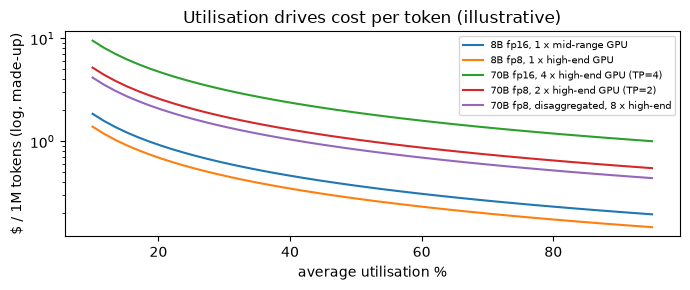

In [13]:
fig, ax = plt.subplots(figsize=(7, 3))
u = np.linspace(0.1, 0.95, 50)
for name, g, p, tps in configs:
    ax.plot(u * 100, [cost_per_million(g, p, tps, x) for x in u], label=name)
ax.set_yscale("log"); ax.set_xlabel("average utilisation %"); ax.set_ylabel("$ / 1M tokens (log, made-up)")
ax.set_title("Utilisation drives cost per token (illustrative)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**What to notice.** Within one configuration, going from 20% to 80% utilisation cuts the cost per token by 4x, which is usually a bigger lever than switching GPUs. Lower-precision formats and disaggregated serving raise tokens per second per GPU. Compare the result with a hosted API's price per token (see [tokens, cost, batch and caching](../../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb)): self-hosting wins only when utilisation stays high or data rules require it.

## 17. Service map

| Need | AWS | Azure | Google Cloud | Neocloud / open source |
|---|---|---|---|---|
| Managed Kubernetes with GPU nodes | EKS (GPU AMIs, Auto Mode with GPU support, Karpenter) | AKS (GPU node pools, NAP) | GKE (GPU and TPU node pools, Autopilot GPU classes) | CoreWeave CKS, Nebius, Crusoe managed Kubernetes |
| GPU drivers and device plugin | EKS-optimized accelerated AMIs / Bottlerocket, or the GPU Operator | AKS GPU images, or the GPU Operator | GKE-managed drivers, or the GPU Operator | NVIDIA GPU Operator, AMD GPU Operator |
| Batch / gang scheduling | Kueue, AWS Batch on EKS, SageMaker HyperPod (EKS or Slurm) | Kueue, Volcano | Kueue (GKE recommends it), Dynamic Workload Scheduler | Kueue, Volcano, KAI Scheduler, Slurm (Slinky, SUNK) |
| Model-aware LLM routing | Gateway API controllers, llm-d / Dynamo on EKS | Gateway API controllers, KAITO (AI toolchain operator) | **GKE Inference Gateway** (GA, powered by llm-d) | Gateway API Inference Extension (Istio, Agentgateway, NGINX Gateway Fabric, Envoy Gateway, kgateway), llm-d Router |
| Model storage | S3 (+ Mountpoint for S3, FSx for Lustre) | Blob Storage (+ BlobFuse, Azure Managed Lustre) | Cloud Storage (+ Cloud Storage FUSE, Parallelstore / Managed Lustre) | object storage + Run:ai Model Streamer, node-local NVMe caches |
| High-speed GPU networking | EFA, UltraClusters | InfiniBand on ND-series VMs | GPUDirect-TCPX/TCPXO, RDMA (A3/A4 VMs) | InfiniBand / RoCE, NVIDIA Network Operator |
| Capacity planning | Capacity Blocks for ML, On-Demand Capacity Reservations | capacity reservations | reservations, Dynamic Workload Scheduler (flex-start / calendar mode) | reserved clusters |

## 18. How to try it for real

**Without a GPU (free, local):**
1. `kind create cluster` (see the deep-dive notebook lab).
2. Install the **fake GPU operator** (open source, from Run:ai / NVIDIA) to make kind nodes advertise fake `nvidia.com/gpu`; practice taints, quotas, and scheduling of GPU Pods.
3. Install **Kueue** (`kubectl apply --server-side -f` the release manifest) and submit two 4-"GPU" Jobs to reproduce section 4.
4. Run **vLLM on CPU** or a tiny model with **llama.cpp / Ollama** in a Deployment to practice probes, Services, HPA/KEDA on a custom metric.
5. Install **KServe** in "raw deployment" mode with a small scikit-learn model to learn `InferenceService`.

**With one real GPU (a workstation or a cheap cloud GPU VM):**

```bash
# minikube can pass an NVIDIA GPU through with the docker driver (see the minikube GPU tutorial)
minikube start --driver=docker --container-runtime=docker --gpus=all
kubectl get nodes -o jsonpath='{.items[*].status.allocatable}'      # look for nvidia.com/gpu
helm install vllm vllm/vllm-stack -f values.yaml                    # vLLM production stack (see its README)
```

**In the cloud:** a GKE, EKS or AKS cluster with one small GPU node pool (L4-class GPUs are a common low-cost choice), the GPU Operator (or the provider's managed driver), then KServe or llm-d's quickstart. Delete the node pool when done: GPUs are billed by the hour.

The guarded cell below only runs `nvidia-smi` if it exists.

In [14]:
if not HAS_NVIDIA_SMI:
    print("skipped: needs an NVIDIA GPU and driver (nvidia-smi)")
else:
    import subprocess
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv"],
                             capture_output=True, text=True, timeout=10)
        print(out.stdout or out.stderr)
    except Exception as e:
        print("skipped: nvidia-smi failed ->", type(e).__name__)

skipped: needs an NVIDIA GPU and driver (nvidia-smi)


## 19. Certification and skills map

| Exam / skill area | What this notebook covers |
|---|---|
| **CKA** (scheduling, autoscaling, CRDs/operators, CNI/CRI) | device plugins and extended resources, DRA objects, taints for GPU pools, operators (GPU Operator, KServe, KubeRay), containerd/CRI-O |
| **CKAD** (workloads, probes, config) | inference Deployments, startup time and probes, KEDA/HPA on custom metrics |
| **CKS** (supply chain, runtime security) | air-gapped mirrors, signed images, sandboxed runtimes (gVisor, Kata) |
| **KCNA** (cloud native fundamentals) | the runtime stack (OCI, runc, containerd), what operators and CRDs are |
| Announced for 2027: **KAIA** (Kubernetes AI Associate), **CKIE** (Certified Kubernetes Inference Engineer) | GPU stack, sharing, DRA, gang scheduling, serving stacks, inference routing, autoscaling, model loading |
| Cloud ML exams (AWS ML Engineer Associate, Azure AI/ML, Google Professional ML Engineer) | GPU instance choice, serving and scaling trade-offs, cost per token, capacity |
| NVIDIA certifications (AI infrastructure and operations tracks) | GPU Operator, MIG, DCGM, networking concepts |

## 20. Recap: cheat sheet

| Topic | Remember this |
|---|---|
| GPU stack | host driver >= what the image's CUDA needs; Container Toolkit + CDI; device plugin or DRA driver; the GPU Operator installs it all |
| Metrics | DCGM exporter; `SM_ACTIVE` beats `GPU_UTIL`; memory "full" is normal for vLLM |
| Sharing | MIG = hardware isolation (production), time-slicing = no isolation (dev), MPS = concurrent with limits |
| DRA | ResourceSlice (catalogue), DeviceClass, ResourceClaim(Template), CEL selectors; GA core in 1.34 |
| Batch | gang scheduling avoids partial-start deadlocks; Kueue (quota + admission), Volcano, KAI Scheduler |
| AMD | ROCm, `amd.com/gpu`, AMD GPU Operator, ROCm builds of vLLM/SGLang |
| Serving | engine (vLLM/SGLang/TRT-LLM) + orchestration (KServe, llm-d, Dynamo, KubeRay, NIM Operator) + routing |
| Routing | Gateway API Inference Extension: InferencePool + endpoint picker; KV/prefix-aware beats round-robin for chat |
| Autoscaling | scale on queue depth / KV-cache use, not GPU util; cold start dominates; scale up fast, down slow |
| Model loading | stream weights (Run:ai streamer), node caches, OCI image volumes / Modelcars; safetensors |
| Training | Kubeflow Trainer TrainJob, JobSet, LWS (multi-node inference); Slurm still strong; Slinky/SUNK bridge them |
| Networking | NVLink in-node, InfiniBand/RoCE/EFA between nodes, GPUDirect RDMA, NCCL; Multus/SR-IOV/Network Operator |
| Clouds | hyperscalers vs neoclouds vs serverless GPUs: capacity, price, portability |
| Runtimes | OCI -> runc/crun -> containerd/CRI-O (CRI); Podman/Buildah rootless; buildx multi-arch; dev containers |
| Cost | $/1M tokens = GPU $/h x GPUs / (tokens/s x 3600 x utilisation) x 1e6; utilisation is the big lever |

## 21. Interview questions

1. **A GPU Pod is Pending with `Insufficient nvidia.com/gpu`, but nodes have GPUs. What do you check?** The device plugin / GPU Operator Pods on those nodes, node `Allocatable`, taints/tolerations, MIG strategy (resource name mismatch such as `nvidia.com/mig-1g.10gb` vs `nvidia.com/gpu`), and whether other Pods hold the GPUs.
2. **MIG vs time-slicing?** MIG partitions the hardware with isolated memory and compute and predictable performance; time-slicing just shares one GPU in turns with no memory isolation. Use MIG for multi-tenant production, time-slicing for dev.
3. **What problem does DRA solve over device plugins?** Device plugins only count identical units; DRA lets drivers publish rich device attributes and lets Pods claim devices with CEL selectors, alternatives, sharing and partitioning, and lets the scheduler reason about them.
4. **Why does distributed training need gang scheduling?** Workers block until all peers join; scheduling Pods one by one can start partial jobs that hold GPUs and deadlock. Gang/queue admission (Kueue, Volcano, KAI) starts all-or-nothing.
5. **How would you autoscale a vLLM deployment?** On queue depth (`num_requests_waiting`) and KV-cache usage or latency SLOs via KEDA/HPA custom metrics or a planner, with a warm minimum, slow scale-down, and fast cold starts (cached images and weights).
6. **What is KV-cache-aware routing and why does it help?** Sending a request to the replica that already holds its prompt prefix in KV cache skips most prefill compute, lowering TTFT and raising throughput; the Gateway API Inference Extension's endpoint picker, llm-d and Dynamo implement it.
7. **What is prefill/decode disaggregation?** Running the compute-heavy prompt processing (prefill) and the memory-bound token generation (decode) on separate worker pools, transferring the KV cache between them (NIXL/RDMA), so each pool is sized and tuned for its phase.
8. **How do you cut model cold-start time?** Smaller images, pre-pulled images, weights streamed from object storage or cached on node NVMe, OCI image volumes/Modelcars, safetensors, quantized weights, and keeping a warm replica.
9. **Kubernetes or Slurm for a training cluster?** Slurm for pure batch HPC with researchers used to `sbatch`; Kubernetes (+ Kueue, Trainer/JobSet) when you also serve models and want one platform; Slinky/SUNK combine them.
10. **What is containerd vs runc vs Docker?** runc creates containers from OCI bundles; containerd manages images and containers and implements the CRI for kubelet; Docker is a developer tool built on containerd. Kubernetes talks to containerd or CRI-O, not to Docker.
11. **How do you estimate cost per million tokens for self-hosting?** GPU hourly cost x number of GPUs divided by tokens per hour at real utilisation; then compare with API prices, including engineering and idle time.

## 22. Further reading

- NVIDIA GPU Operator docs: https://docs.nvidia.com/datacenter/cloud-native/gpu-operator/latest/
- NVIDIA MIG user guide: https://docs.nvidia.com/datacenter/tesla/mig-user-guide/
- GPU sharing (time-slicing) with the GPU Operator: https://docs.nvidia.com/datacenter/cloud-native/gpu-operator/latest/gpu-sharing.html
- DCGM exporter: https://github.com/NVIDIA/dcgm-exporter
- Kubernetes Dynamic Resource Allocation: https://kubernetes.io/docs/concepts/scheduling-eviction/dynamic-resource-allocation/
- NVIDIA device plugin (MIG strategies, time-slicing, MPS): https://github.com/NVIDIA/k8s-device-plugin ; MIG supported profiles: https://docs.nvidia.com/datacenter/tesla/mig-user-guide/supported-mig-profiles.html
- Kueue: https://kueue.sigs.k8s.io/docs/overview/ ; Volcano: https://volcano.sh/ ; KAI Scheduler: https://github.com/NVIDIA/KAI-Scheduler
- AMD GPU Operator: https://instinct.docs.amd.com/projects/gpu-operator/en/latest/ ; ROCm release notes: https://rocm.docs.amd.com/en/latest/about/release-notes.html
- KServe: https://kserve.github.io/website/ ; llm-d: https://llm-d.ai/ ; vLLM production stack: https://github.com/vllm-project/production-stack
- NVIDIA Dynamo: https://github.com/ai-dynamo/dynamo ; Dynamo-Triton: https://developer.nvidia.com/dynamo-triton ; NIM Operator: https://docs.nvidia.com/nim-operator/latest/index.html ; KubeRay: https://docs.ray.io/en/latest/cluster/kubernetes/index.html ; SGLang: https://docs.sglang.ai/
- Gateway API Inference Extension: https://gateway-api-inference-extension.sigs.k8s.io/ (InferencePool: https://gateway-api-inference-extension.sigs.k8s.io/api-types/inferencepool/) ; llm-d InferenceObjective: https://llm-d.ai/docs/api-reference/inferenceobjective
- vLLM metrics: https://docs.vllm.ai/en/latest/usage/metrics.html ; Run:ai Model Streamer in vLLM: https://docs.vllm.ai/en/latest/models/extensions/runai_model_streamer.html
- KServe Modelcars (OCI storage): https://kserve.github.io/website/docs/model-serving/storage/providers/oci ; Kubernetes image volumes: https://kubernetes.io/docs/tasks/configure-pod-container/image-volumes/
- dcgm-exporter metric names: https://github.com/NVIDIA/dcgm-exporter/blob/main/etc/default-counters.csv
- NVIDIA DRA driver for GPUs: https://github.com/kubernetes-sigs/dra-driver-nvidia-gpu ; DRANET: https://github.com/kubernetes-sigs/dranet
- Kubernetes v1.37 DRA updates: https://kubernetes.io/blog/2026/09/03/kubernetes-v1-37-dra-updates/ ; workload-aware (gang) scheduling: https://kubernetes.io/blog/2026/09/08/kubernetes-v1-37-advancing-workload-aware-scheduling/
- CNCF AI Conformance launch: https://www.cncf.io/blog/2025/11/11/cncf-launches-certified-kubernetes-ai-conformance-program-to-standardize-ai-workloads-on-kubernetes/
- Kubeflow Trainer: https://www.kubeflow.org/docs/components/trainer/ ; JobSet: https://jobset.sigs.k8s.io/ ; LeaderWorkerSet: https://lws.sigs.k8s.io/
- Slinky slurm-operator: https://github.com/SlinkyProject/slurm-operator ; CoreWeave SUNK: https://docs.coreweave.com/docs/products/sunk
- AWS EFA: https://docs.aws.amazon.com/AWSEC2/latest/UserGuide/efa.html ; NVIDIA Network Operator: https://docs.nvidia.com/networking/display/kubernetes2640/overview.html
- CNCF Kubernetes AI Conformance: https://github.com/cncf/k8s-ai-conformance
- containerd: https://containerd.io/ ; CRI-O: https://cri-o.io/ ; Podman: https://podman.io/ ; Docker buildx multi-platform: https://docs.docker.com/build/building/multi-platform/ ; Dev Containers spec: https://containers.dev/
- Papers: Kwon et al., *Efficient Memory Management for Large Language Model Serving with PagedAttention* (vLLM), SOSP 2023, arXiv:2309.06180; Zhong et al., *DistServe: Disaggregating Prefill and Decoding for Goodput-optimized LLM Serving*, OSDI 2024, arXiv:2401.09670; Zheng et al., *SGLang: Efficient Execution of Structured Language Model Programs*, arXiv:2312.07104.

Related notebooks in this repo: [Kubernetes deep dive for AI workloads](02_kubernetes_deep_dive_for_ai_workloads.ipynb), [Kubernetes overview](01_kubernetes.ipynb), [Helm and GitOps](../03_helm_and_gitops.ipynb), [Docker for ML](../02_docker_for_ml.ipynb), [LLM inference optimization](../../08_LLM/13_inference_optimization.ipynb), [LLM caching and KV-aware routing](../../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb), [distributed training](../../05_Deep_Learning/11_distributed_training.ipynb), [designing for 100 million users](../../22_ML_System_Design/12_designing_for_100_million_users.ipynb).